# CustOmics on Pan-cancer: 32-class cancer type classification

**Goal:** classify 8 314 TCGA patients into 32 primary cancer types from 4 omics layers (mRNA, DNA methylation,
CNV, miRNA) with the best architecture from `reference_material/`, and save the trained models and results to
`results/pancancer/`.

**Data:** MLOmics `Pan-cancer/Original` holds 3 217 mRNA, 3 139 methylation, 3 105 CNV and 383 miRNA features,
already z-scored with no missing values.

**Chosen model: CustOmics with direct fusion of 4 omics (4 × 64 = 256-D).** It is the best pan-cancer model in the
reference notebooks:

| Source | Model | Accuracy | Macro-F1 | NMI | ARI |
|---|---|---|---|---|---|
| `customics_pancancer1.ipynb` | 3 omics, central VAE (64-D) | 0.9667 ± 0.0023 | 0.9427 ± 0.0126 | 0.9610 | 0.9511 |
| `custOmics2.ipynb` | **4 omics, direct fusion (256-D)** | **0.9725 ± 0.0041** | **0.9640 ± 0.0051** | **0.9677** | **0.9581** |

It is the same model code as `01_brca_customics.ipynb`, with these corrections over the reference run:

* early stopping on an inner validation split rather than on the test fold, so test scores are not optimistically biased;
* the best-epoch weights are really restored (`copy.deepcopy` instead of a shallow `state_dict().copy()`);
* class-weighted cross-entropy for the rare cancer types (one class has only 9 patients);
* a phase-1 auxiliary classification head per omics, following the CustOmics paper.

In [1]:
import os, copy, json, random, time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.impute import SimpleImputer
from sklearn.manifold import TSNE
from sklearn.metrics import (accuracy_score, adjusted_rand_score, classification_report, confusion_matrix,
                             f1_score, normalized_mutual_info_score, precision_score, recall_score,
                             roc_auc_score, silhouette_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
N_FOLDS = 5
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA_DIR = "data/MLOmics/Main_Dataset/Classification_datasets/Pan-cancer/Original"
RESULTS_DIR = "results/pancancer"
os.makedirs(RESULTS_DIR, exist_ok=True)


def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


set_seed(SEED)
print("Device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Load data

In [2]:
OMICS = ["mRNA", "Methy", "CNV", "miRNA"]

X_all = {m: pd.read_csv(os.path.join(DATA_DIR, f"Pan-cancer_{m}.csv"), index_col=0).T for m in OMICS}  # patients x features
y = pd.read_csv(os.path.join(DATA_DIR, "Pan-cancer_label_num.csv"))["Label"].to_numpy()

patients = X_all["mRNA"].index
assert all(X_all[m].index.equals(patients) for m in OMICS) and len(y) == len(patients)
N_CLASSES = len(np.unique(y))

print(f"{len(patients)} patients, {N_CLASSES} cancer types\n")
print(pd.DataFrame({m: [X_all[m].shape[1], int(X_all[m].isna().sum().sum())] for m in OMICS},
                   index=["features", "missing values"]))
counts = pd.Series(y).value_counts().sort_index()
print(f"\nPatients per class: min={counts.min()} (class {counts.idxmin()}), max={counts.max()} (class {counts.idxmax()})")

8314 patients, 32 cancer types

                mRNA  Methy   CNV  miRNA
features        3217   3139  3105    383
missing values     0      0     0      0

Patients per class: min=9 (class 18), max=757 (class 2)


## 2. Model: CustOmics mixed integration

* **Phase 1 – per-omics autoencoders.** Each omics source has its own encoder/decoder
  (`Linear → BatchNorm → ReLU → Dropout → Linear → BatchNorm → ReLU`) that compresses it to a 64-D sub-latent.
  As in the CustOmics paper, each source also gets a small auxiliary classifier head in this phase, so the sub-latent
  is pushed to hold subtype signal, not only reconstructable variance.
* **Phase 2 – fusion + classification.** The sub-latents are fused and fed to the classifier; everything is fine-tuned
  end-to-end with `reconstruction + 2 × cross-entropy`.
  * `fusion="direct"`: concatenate the sub-latents (4 × 64 = 256-D) → classifier. This was the **best model in
    `reference_material`** (`custOmics2.ipynb`, pan-cancer acc 0.9725 / macro-F1 0.9640).
  * `fusion="vae"`: concatenate → central VAE with MMD regularisation → classifier on μ (the original CustOmics design,
    `customics_pancancer1.ipynb`, acc 0.9667 / macro-F1 0.9427).
* Cross-entropy is **class-weighted** (inverse class frequency), the imbalance fix proposed in the synopsis.

In [3]:
class SourceAE(nn.Module):
    """Per-omics autoencoder: compresses one omics source to a small latent vector."""
    def __init__(self, in_dim, latent_dim, hidden=256, dropout=0.2):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, latent_dim), nn.BatchNorm1d(latent_dim), nn.ReLU())
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden), nn.BatchNorm1d(hidden), nn.ReLU(),
            nn.Linear(hidden, in_dim))


class CustOmics(nn.Module):
    """Per-omics autoencoders -> fusion ("direct" concat or central "vae") -> classifier."""
    def __init__(self, in_dims, n_classes, latent_dim=64, fusion="direct", central_dim=64, hidden=256, dropout=0.2):
        super().__init__()
        self.omics, self.fusion = list(in_dims), fusion
        self.aes = nn.ModuleDict({m: SourceAE(d, latent_dim, hidden, dropout) for m, d in in_dims.items()})
        self.aux_heads = nn.ModuleDict({m: nn.Linear(latent_dim, n_classes) for m in in_dims})  # phase 1 only
        fused_dim = latent_dim * len(in_dims)
        if fusion == "vae":
            self.central_enc = nn.Sequential(nn.Linear(fused_dim, 128), nn.BatchNorm1d(128), nn.ReLU())
            self.fc_mu, self.fc_logvar = nn.Linear(128, central_dim), nn.Linear(128, central_dim)
            self.central_dec = nn.Sequential(nn.Linear(central_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
                                             nn.Linear(128, fused_dim))
            fused_dim = central_dim
        self.classifier = nn.Sequential(nn.Linear(fused_dim, 128), nn.BatchNorm1d(128), nn.ReLU(),
                                        nn.Dropout(dropout), nn.Linear(128, n_classes))

    def encode(self, xs):
        return {m: self.aes[m].encoder(xs[m]) for m in self.omics}

    def forward(self, xs):
        z = self.encode(xs)
        out = {"recon": {m: self.aes[m].decoder(z[m]) for m in self.omics}}
        h = torch.cat([z[m] for m in self.omics], dim=1)
        if self.fusion == "vae":
            e = self.central_enc(h)
            mu, logvar = self.fc_mu(e), self.fc_logvar(e)
            zc = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
            out.update(h=h, h_hat=self.central_dec(zc), zc=zc)
            h = mu
        out["latent"], out["logits"] = h, self.classifier(h)
        return out


def mmd(z):
    """MMD between z and samples of N(0, I), RBF kernel with bandwidth = latent dim."""
    prior = torch.randn_like(z)
    k = lambda a, b: torch.exp(-torch.cdist(a, b).pow(2) / z.shape[1])
    return k(z, z).mean() + k(prior, prior).mean() - 2 * k(z, prior).mean()

## 3. Training and evaluation

* **Stratified 5-fold CV.** Inside every training fold, 15 % is held out (stratified) as a validation set used only
  for early stopping. The test fold is never touched during training or model selection.
* **Preprocessing** (median imputation + standardisation per omics) is fitted on the training patients of each fold only.
* The best epoch is chosen by the lowest validation cross-entropy, and a real copy of its weights is restored
  (`copy.deepcopy`). The reference notebooks used `state_dict().copy()`, which is a shallow copy and silently
  keeps the *last* weights.
* Metrics on each test fold: accuracy, macro precision / recall / F1, ROC-AUC (one-vs-rest), NMI and ARI.

In [4]:
CFG = dict(omics=OMICS, latent_dim=64, fusion="direct", hidden=256, dropout=0.2, lr=1e-3, weight_decay=1e-4,
           batch_size=64, p1_epochs=50, p2_epochs=150, min_epochs=30, patience=20, ce_weight=2.0, mmd_weight=1.0)
METRICS = ["accuracy", "precision", "recall", "f1_macro", "roc_auc", "nmi", "ari"]
FOLDS = list(StratifiedKFold(N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y))


def fit_preprocessors(idx, omics):
    """Median-impute + standardise each omics source, fitted on the given (training) patients only."""
    return {m: make_pipeline(SimpleImputer(strategy="median"), StandardScaler()).fit(X_all[m].iloc[idx])
            for m in omics}


def to_tensors(idx, pipes):
    return {m: torch.tensor(p.transform(X_all[m].iloc[idx]), dtype=torch.float32, device=DEVICE)
            for m, p in pipes.items()}


def minibatches(n, batch_size):
    idx = torch.randperm(n, device=DEVICE)
    return [b for b in idx.split(batch_size) if len(b) > 1]  # BatchNorm needs > 1 sample


@torch.no_grad()
def predict(model, xs, batch_size=1024):
    model.eval()
    n = len(next(iter(xs.values())))
    probs, latents = [], []
    for s in range(0, n, batch_size):
        out = model({m: x[s:s + batch_size] for m, x in xs.items()})
        probs.append(F.softmax(out["logits"], dim=1).cpu())
        latents.append(out["latent"].cpu())
    return torch.cat(probs).numpy(), torch.cat(latents).numpy()


def train_model(xs_tr, y_tr, xs_va, y_va, cfg, class_weights):
    omics = cfg["omics"]
    model = CustOmics({m: xs_tr[m].shape[1] for m in omics}, N_CLASSES, cfg["latent_dim"], cfg["fusion"],
                      hidden=cfg["hidden"], dropout=cfg["dropout"]).to(DEVICE)
    ce = nn.CrossEntropyLoss(weight=class_weights)
    n = len(y_tr)

    # Phase 1: each omics autoencoder learns to reconstruct its source and predict the label
    opt = torch.optim.Adam([*model.aes.parameters(), *model.aux_heads.parameters()],
                           lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    for _ in range(cfg["p1_epochs"]):
        model.train()
        for b in minibatches(n, cfg["batch_size"]):
            z = model.encode({m: xs_tr[m][b] for m in omics})
            loss = sum(F.mse_loss(model.aes[m].decoder(z[m]), xs_tr[m][b]) + ce(model.aux_heads[m](z[m]), y_tr[b])
                       for m in omics)
            opt.zero_grad(); loss.backward(); opt.step()

    # Phase 2: fuse the sub-latents and fine-tune everything end-to-end
    opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"], weight_decay=cfg["weight_decay"])
    best = {"loss": float("inf"), "epoch": 0, "state": None}
    for epoch in range(1, cfg["p2_epochs"] + 1):
        model.train()
        for b in minibatches(n, cfg["batch_size"]):
            xb = {m: xs_tr[m][b] for m in omics}
            out = model(xb)
            loss = sum(F.mse_loss(out["recon"][m], xb[m]) for m in omics) + cfg["ce_weight"] * ce(out["logits"], y_tr[b])
            if cfg["fusion"] == "vae":
                loss = loss + F.mse_loss(out["h_hat"], out["h"].detach()) + cfg["mmd_weight"] * mmd(out["zc"])
            opt.zero_grad(); loss.backward(); opt.step()

        # early stopping on the inner validation split
        model.eval()
        with torch.no_grad():
            val_loss = ce(model(xs_va)["logits"], y_va).item()
        if val_loss < best["loss"] - 1e-4:
            best = {"loss": val_loss, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        elif epoch >= cfg["min_epochs"] and epoch - best["epoch"] >= cfg["patience"]:
            break
    model.load_state_dict(best["state"])
    return model, best["epoch"]


def scores(y_true, proba):
    y_pred = proba.argmax(1)
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro"),
            "roc_auc": roc_auc_score(y_true, proba, multi_class="ovr", labels=np.arange(N_CLASSES)),
            "nmi": normalized_mutual_info_score(y_true, y_pred),
            "ari": adjusted_rand_score(y_true, y_pred)}


def run_cv(name, cfg):
    """Stratified 5-fold CV; returns per-fold metrics, out-of-fold predictions/latents and the trained models."""
    rows, models, oof_proba, oof_latent = [], [], np.zeros((len(y), N_CLASSES)), None
    t0 = time.time()
    for fold, (train_idx, test_idx) in enumerate(FOLDS, 1):
        set_seed(SEED + fold)
        fit_idx, val_idx = train_test_split(train_idx, test_size=0.15, stratify=y[train_idx], random_state=SEED)
        pipes = fit_preprocessors(fit_idx, cfg["omics"])
        xs_fit, xs_val, xs_test = (to_tensors(i, pipes) for i in (fit_idx, val_idx, test_idx))
        y_fit, y_val = (torch.tensor(y[i], device=DEVICE) for i in (fit_idx, val_idx))
        counts = np.bincount(y[fit_idx], minlength=N_CLASSES)
        class_weights = torch.tensor(len(fit_idx) / (N_CLASSES * counts), dtype=torch.float32, device=DEVICE)

        model, best_epoch = train_model(xs_fit, y_fit, xs_val, y_val, cfg, class_weights)
        proba, latent = predict(model, xs_test)
        oof_proba[test_idx] = proba
        if oof_latent is None:
            oof_latent = np.zeros((len(y), latent.shape[1]), dtype=np.float32)
        oof_latent[test_idx] = latent
        rows.append({"fold": fold, **scores(y[test_idx], proba), "best_epoch": best_epoch})
        models.append({"state_dict": {k: v.cpu() for k, v in model.state_dict().items()}, "preprocess": pipes,
                       "in_dims": {m: xs_fit[m].shape[1] for m in cfg["omics"]}})
        print(f"[{name}] fold {fold}: acc={rows[-1]['accuracy']:.4f}  macro-F1={rows[-1]['f1_macro']:.4f}  "
              f"best epoch={best_epoch}")
    print(f"[{name}] finished in {time.time() - t0:.0f}s\n")
    return {"name": name, "cfg": cfg, "folds": pd.DataFrame(rows), "oof_proba": oof_proba,
            "oof_latent": oof_latent, "models": models}


def summary_table(runs):
    """mean ± std over the 5 test folds for every run."""
    return pd.DataFrame({r["name"]: {k: f"{r['folds'][k].mean():.4f} ± {r['folds'][k].std():.4f}" for k in METRICS}
                         for r in runs}).T


def save_run(run, out_dir, class_names=None):
    """Save fold models, preprocessing, metrics and out-of-fold predictions of one run."""
    os.makedirs(os.path.join(out_dir, "models"), exist_ok=True)
    for fold, m in enumerate(run["models"], 1):
        torch.save({"state_dict": m["state_dict"], "in_dims": m["in_dims"], "n_classes": N_CLASSES, "config": run["cfg"]},
                   os.path.join(out_dir, "models", f"fold_{fold}.pt"))
        joblib.dump(m["preprocess"], os.path.join(out_dir, "models", f"preprocess_fold_{fold}.joblib"))
    with open(os.path.join(out_dir, "config.json"), "w") as f:
        json.dump({"name": run["name"], **run["cfg"], "seed": SEED, "n_folds": N_FOLDS}, f, indent=2)

    run["folds"].to_csv(os.path.join(out_dir, "cv_metrics_per_fold.csv"), index=False)
    summary = run["folds"][METRICS].agg(["mean", "std"]).T
    summary.to_csv(os.path.join(out_dir, "cv_metrics_summary.csv"))

    y_pred = run["oof_proba"].argmax(1)
    preds = pd.DataFrame(run["oof_proba"], index=patients, columns=[f"p_class_{c}" for c in range(N_CLASSES)])
    preds.insert(0, "y_pred", y_pred); preds.insert(0, "y_true", y)
    preds.to_csv(os.path.join(out_dir, "oof_predictions.csv"), index_label="patient")
    np.save(os.path.join(out_dir, "oof_latent.npy"), run["oof_latent"])

    report = pd.DataFrame(classification_report(y, y_pred, target_names=class_names, output_dict=True,
                                                zero_division=0)).T
    report.to_csv(os.path.join(out_dir, "per_class_metrics.csv"))
    return summary, report

## 4. Train and evaluate (5-fold CV)

In [5]:
run = run_cv("Direct fusion | 4 omics | 64-D", dict(CFG))

[Direct fusion | 4 omics | 64-D] fold 1: acc=0.9753  macro-F1=0.9571  best epoch=14


[Direct fusion | 4 omics | 64-D] fold 2: acc=0.9759  macro-F1=0.9692  best epoch=53


[Direct fusion | 4 omics | 64-D] fold 3: acc=0.9699  macro-F1=0.9605  best epoch=14


[Direct fusion | 4 omics | 64-D] fold 4: acc=0.9711  macro-F1=0.9600  best epoch=3


[Direct fusion | 4 omics | 64-D] fold 5: acc=0.9771  macro-F1=0.9661  best epoch=7
[Direct fusion | 4 omics | 64-D] finished in 270s



## 5. Results

In [6]:
summary, per_class = save_run(run, RESULTS_DIR)
display(run["folds"].round(4))
print("\nMean ± std over 5 folds")
display(summary.round(4))

reference = pd.DataFrame(
    {"accuracy": [0.9667, 0.9725], "f1_macro": [0.9427, 0.9640], "nmi": [0.9610, 0.9677], "ari": [0.9511, 0.9581]},
    index=["Reference: 3 omics + central VAE", "Reference: 4 omics direct fusion"])
reference.loc["This notebook: 4 omics direct fusion"] = summary.loc[["accuracy", "f1_macro", "nmi", "ari"], "mean"]
reference.to_csv(os.path.join(RESULTS_DIR, "comparison_with_reference.csv"))
print("\nComparison with reference_material (5-fold means)")
display(reference.round(4))

,fold,accuracy,precision,recall,f1_macro,roc_auc,nmi,ari,best_epoch
0,1,0.9753,0.9578,0.9645,0.9571,0.9989,0.9682,0.9620,14
1,2,0.9759,0.9717,0.9675,0.9692,0.9996,0.9709,0.9652,53
2,3,0.9699,0.9665,0.9591,0.9605,0.9978,0.9648,0.9538,14
3,4,0.9711,0.9561,0.9657,0.9600,0.9995,0.9626,0.9532,3
4,5,0.9771,0.9631,0.9702,0.9661,0.9997,0.9711,0.9659,7



Mean ± std over 5 folds


,mean,std
accuracy,0.9739,0.0032
precision,0.9630,0.0064
recall,0.9654,0.0041
f1_macro,0.9626,0.0049
roc_auc,0.9991,0.0008
nmi,0.9675,0.0038
ari,0.9600,0.0061



Comparison with reference_material (5-fold means)


,accuracy,f1_macro,nmi,ari
Reference: 3 omics + central VAE,0.9667,0.9427,0.9610,0.9511
Reference: 4 omics direct fusion,0.9725,0.9640,0.9677,0.9581
This notebook: 4 omics direct fusion,0.9739,0.9626,0.9675,0.9600


In [7]:
print("Per-class metrics (pooled out-of-fold predictions), sorted by F1")
display(per_class.drop(["accuracy", "macro avg", "weighted avg"]).sort_values("f1-score").round(3))

Per-class metrics (pooled out-of-fold predictions), sorted by F1


,precision,recall,f1-score,support
22,0.816,0.780,0.798,91.0
7,0.879,0.889,0.884,180.0
4,0.912,0.861,0.886,36.0
18,0.818,1.000,0.900,9.0
9,0.899,0.954,0.925,65.0
5,0.918,0.947,0.933,285.0
25,0.942,0.929,0.935,365.0
30,0.945,0.945,0.945,55.0
16,0.965,0.930,0.947,356.0
6,0.904,1.000,0.949,47.0


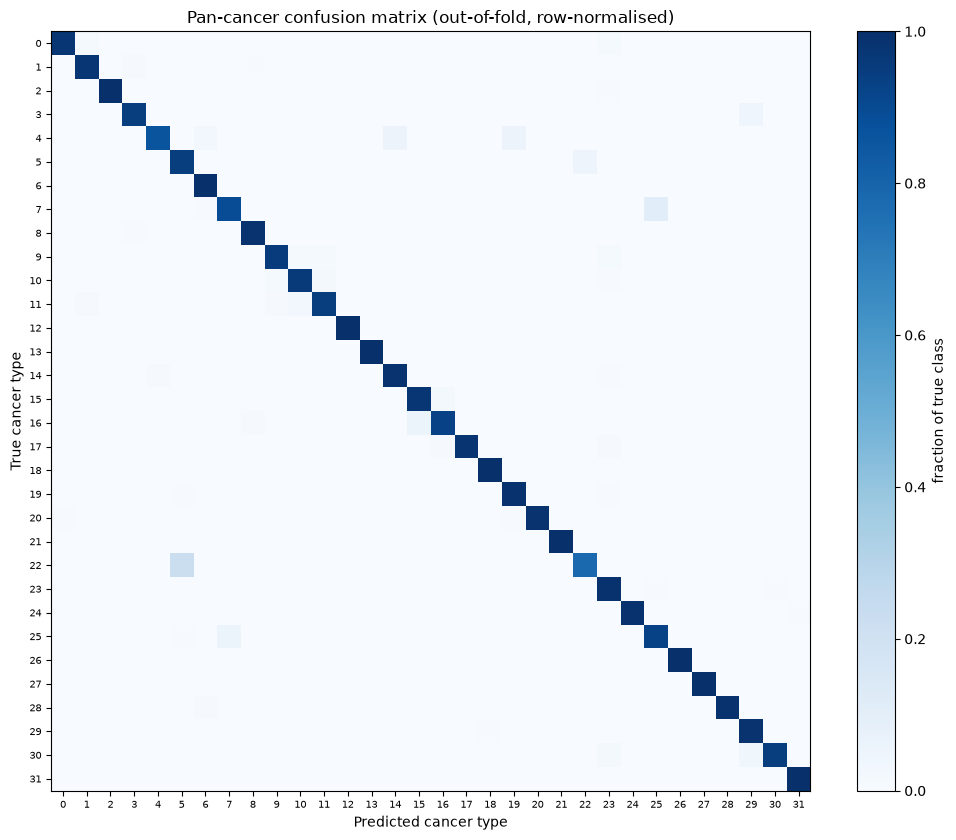

In [8]:
y_pred = run["oof_proba"].argmax(1)
cm = confusion_matrix(y, y_pred, normalize="true")

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
ax.tick_params(labelsize=7)
ax.set_xlabel("Predicted cancer type"); ax.set_ylabel("True cancer type")
ax.set_title("Pan-cancer confusion matrix (out-of-fold, row-normalised)")
plt.colorbar(im, fraction=0.046, label="fraction of true class"); plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "confusion_matrix.png"), dpi=200); plt.show()

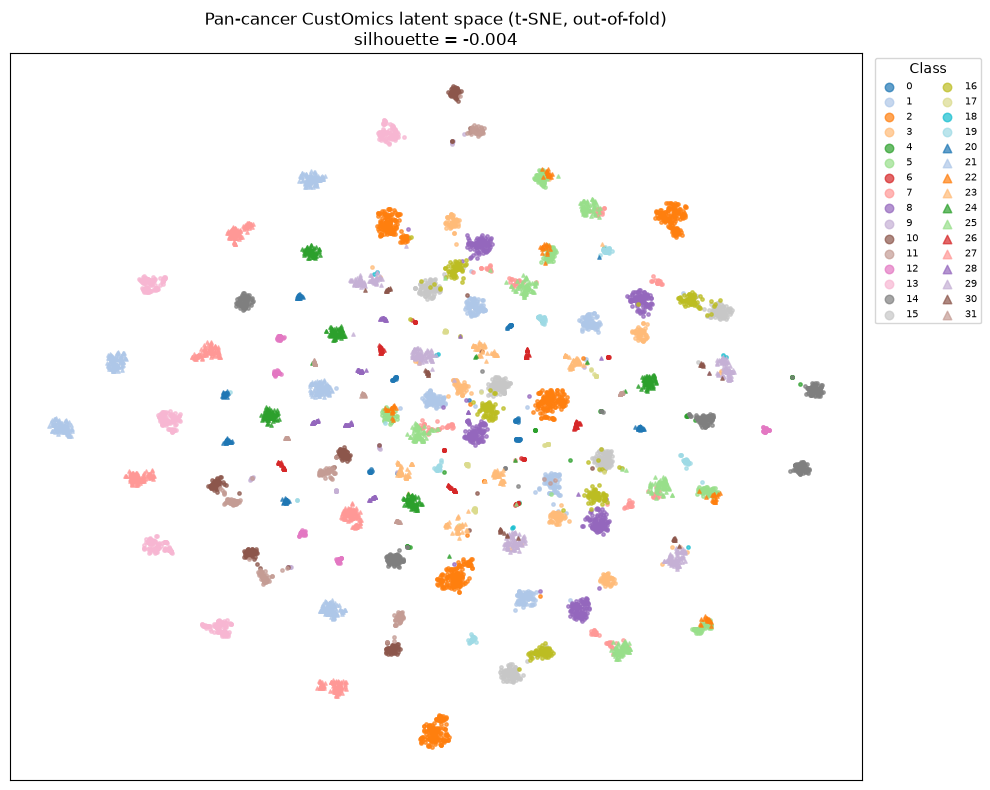

In [9]:
# Latent space: every patient is embedded by the fold model that never saw it during training
xy = TSNE(n_components=2, init="pca", perplexity=40, random_state=SEED).fit_transform(run["oof_latent"])

fig, ax = plt.subplots(figsize=(10, 8))
cmap = plt.get_cmap("tab20", 20)
markers = ["o", "^"]
for c in range(N_CLASSES):
    pts = xy[y == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=6, alpha=0.7, color=cmap(c % 20), marker=markers[c // 20], label=str(c))
ax.set_title(f"Pan-cancer CustOmics latent space (t-SNE, out-of-fold)\n"
             f"silhouette = {silhouette_score(run['oof_latent'], y):.3f}")
ax.set_xticks([]); ax.set_yticks([])
ax.legend(title="Class", ncol=2, fontsize=7, markerscale=2.5, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "latent_tsne.png"), dpi=200); plt.show()